In [3]:
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
train.shape

(891, 12)

In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [4]:
train["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [5]:
train.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [6]:
train.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [7]:
train.groupby("Embarked")["Survived"].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

In [8]:
train.groupby(["Sex", "Pclass"])["Survived"].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

In [9]:
train.groupby(["Sex", "Pclass"])["Survived"].count()

Sex     Pclass
female  1          94
        2          76
        3         144
male    1         122
        2         108
        3         347
Name: Survived, dtype: int64

In [10]:
train.groupby("Survived")["Age"].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

In [11]:
train.groupby("Survived")["Age"].median()

Survived
0    28.0
1    28.0
Name: Age, dtype: float64

In [12]:
train.groupby("Survived")["Age"].count()

Survived
0    424
1    290
Name: Age, dtype: int64

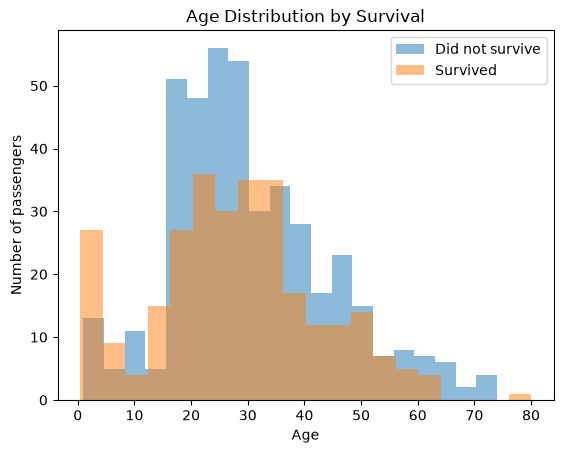

In [13]:
import matplotlib.pyplot as plt

train[train["Survived"] == 0]["Age"].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="Did not survive"
)

train[train["Survived"] == 1]["Age"].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="Survived"
)

plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.title("Age Distribution by Survival")
plt.legend()
plt.show()

In [14]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1

In [15]:
train.groupby("FamilySize")["Survived"].mean()

FamilySize
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64

In [16]:
train["FamilySize"].value_counts().sort_index()

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

In [17]:
train.groupby("Survived")["Fare"].mean()

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64

In [18]:
train.groupby("Survived")["Fare"].median()

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64

In [19]:
train.groupby("Survived")["Fare"].count()

Survived
0    549
1    342
Name: Fare, dtype: int64

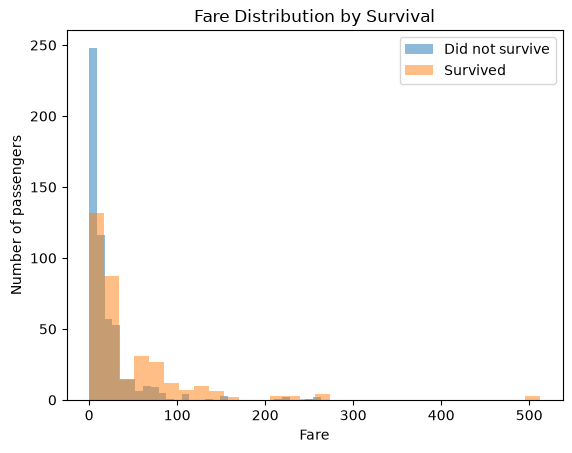

In [20]:
train[train["Survived"] == 0]["Fare"].plot(
    kind="hist",
    bins=30,
    alpha=0.5,
    label="Did not survive"
)

train[train["Survived"] == 1]["Fare"].plot(
    kind="hist",
    bins=30,
    alpha=0.5,
    label="Survived"
)

plt.xlabel("Fare")
plt.ylabel("Number of passengers")
plt.title("Fare Distribution by Survival")
plt.legend()
plt.show()

In [21]:
train.groupby("Survived")["Age"].apply(lambda x: x.isna().sum())

Survived
0    125
1     52
Name: Age, dtype: int64

In [22]:
train.groupby("Pclass")["Age"].apply(lambda x: x.isna().sum())

Pclass
1     30
2     11
3    136
Name: Age, dtype: int64

In [23]:
train.groupby("Pclass")["Cabin"].apply(lambda x: x.isna().sum())

Pclass
1     40
2    168
3    479
Name: Cabin, dtype: int64

In [24]:
train[train["Embarked"].isna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN,1
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN,1


In [25]:
X = train.drop("Survived", axis=1)
y = train["Survived"]

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

In [28]:
categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [30]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [31]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [32]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [33]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PassengerId','Pclass','Name',...,'Cabin','Embarked','FamilySize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

In [34]:
y_pred = model.predict(X_val)

In [35]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_val, y_pred)

print("Validation accuracy:", accuracy)

Validation accuracy: 0.8044692737430168


[[98 12]
 [23 46]]


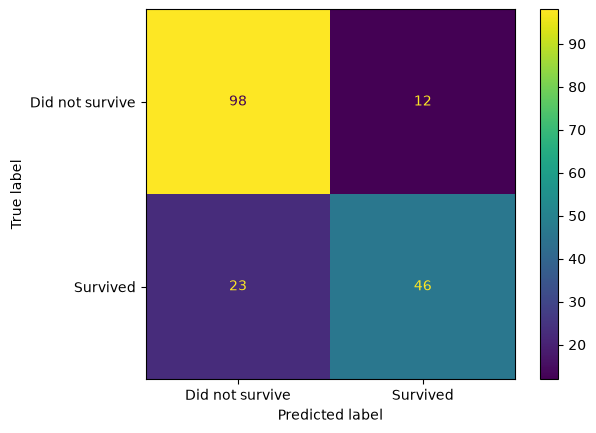

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did not survive", "Survived"]
).plot()

plt.show()

In [37]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred,
    target_names=["Did not survive", "Survived"]
))

                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



In [38]:
from sklearn.neighbors import KNeighborsClassifier

In [39]:
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

In [40]:
knn_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PassengerId','Pclass','Name',...,'Cabin','Embarked','FamilySize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

In [41]:
knn_pred = knn_model.predict(X_val)

In [42]:
from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_val, knn_pred)

print("KNN validation accuracy:", knn_accuracy)

KNN validation accuracy: 0.8100558659217877


In [43]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_val, knn_pred))

print(classification_report(
    y_val,
    knn_pred,
    target_names=["Did not survive", "Survived"]
))

[[98 12]
 [22 47]]
                 precision    recall  f1-score   support

Did not survive       0.82      0.89      0.85       110
       Survived       0.80      0.68      0.73        69

       accuracy                           0.81       179
      macro avg       0.81      0.79      0.79       179
   weighted avg       0.81      0.81      0.81       179



In [44]:
results = []

for k in range(1, 21):
    knn = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    knn.fit(X_train, y_train)

    pred = knn.predict(X_val)

    accuracy = accuracy_score(y_val, pred)

    results.append((k, accuracy))

results

[(1, 0.7318435754189944),
 (2, 0.7877094972067039),
 (3, 0.8212290502793296),
 (4, 0.8044692737430168),
 (5, 0.8100558659217877),
 (6, 0.7932960893854749),
 (7, 0.7932960893854749),
 (8, 0.7932960893854749),
 (9, 0.7821229050279329),
 (10, 0.776536312849162),
 (11, 0.7932960893854749),
 (12, 0.7877094972067039),
 (13, 0.7988826815642458),
 (14, 0.8156424581005587),
 (15, 0.7988826815642458),
 (16, 0.7877094972067039),
 (17, 0.7988826815642458),
 (18, 0.7988826815642458),
 (19, 0.7821229050279329),
 (20, 0.7932960893854749)]

In [45]:
for k, accuracy in results:
    print(f"K={k:2d}  Accuracy={accuracy:.4f}")

K= 1  Accuracy=0.7318
K= 2  Accuracy=0.7877
K= 3  Accuracy=0.8212
K= 4  Accuracy=0.8045
K= 5  Accuracy=0.8101
K= 6  Accuracy=0.7933
K= 7  Accuracy=0.7933
K= 8  Accuracy=0.7933
K= 9  Accuracy=0.7821
K=10  Accuracy=0.7765
K=11  Accuracy=0.7933
K=12  Accuracy=0.7877
K=13  Accuracy=0.7989
K=14  Accuracy=0.8156
K=15  Accuracy=0.7989
K=16  Accuracy=0.7877
K=17  Accuracy=0.7989
K=18  Accuracy=0.7989
K=19  Accuracy=0.7821
K=20  Accuracy=0.7933


In [46]:
from sklearn.model_selection import GridSearchCV

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

param_grid = {
    "classifier__n_neighbors": range(1, 21)
}

grid_search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': range(1, 21)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed dur

In [47]:
print("Best K:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)

Best K: {'classifier__n_neighbors': 20}
Best CV accuracy: 0.8259529203191175


In [48]:
best_knn = grid_search.best_estimator_

knn_cv_pred = best_knn.predict(X_val)

print(
    "Validation accuracy:",
    accuracy_score(y_val, knn_cv_pred)
)

Validation accuracy: 0.7932960893854749


In [49]:
from sklearn.tree import DecisionTreeClassifier

In [50]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

In [51]:
tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PassengerId','Pclass','Name',...,'Cabin','Embarked','FamilySize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

In [52]:
tree_pred = tree_model.predict(X_val)

In [53]:
tree_accuracy = accuracy_score(y_val, tree_pred)

print("Decision Tree validation accuracy:", tree_accuracy)

Decision Tree validation accuracy: 0.7821229050279329


In [54]:
print(classification_report(
    y_val,
    tree_pred,
    target_names=["Did not survive", "Survived"]
))

                 precision    recall  f1-score   support

Did not survive       0.81      0.84      0.83       110
       Survived       0.73      0.70      0.71        69

       accuracy                           0.78       179
      macro avg       0.77      0.77      0.77       179
   weighted avg       0.78      0.78      0.78       179



In [55]:
tree_train_pred = tree_model.predict(X_train)

print(
    "Training accuracy:",
    accuracy_score(y_train, tree_train_pred)
)

print(
    "Validation accuracy:",
    accuracy_score(y_val, tree_pred)
)

Training accuracy: 0.9831460674157303
Validation accuracy: 0.7821229050279329


In [56]:
tree_results = []

for depth in range(2, 9):

    tree = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    val_pred = tree.predict(X_val)

    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    tree_results.append(
        (depth, train_acc, val_acc)
    )

for depth, train_acc, val_acc in tree_results:
    print(
        f"Depth={depth}  "
        f"Train={train_acc:.4f}  "
        f"Validation={val_acc:.4f}"
    )

Depth=2  Train=0.8048  Validation=0.7598
Depth=3  Train=0.8287  Validation=0.8045
Depth=4  Train=0.8385  Validation=0.7821
Depth=5  Train=0.8638  Validation=0.7598
Depth=6  Train=0.8750  Validation=0.7709
Depth=7  Train=0.8890  Validation=0.7654
Depth=8  Train=0.9087  Validation=0.7933


In [57]:
from sklearn.model_selection import GridSearchCV

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

tree_param_grid = {
    "classifier__max_depth": range(2, 11)
}

tree_grid = GridSearchCV(
    tree_pipeline,
    tree_param_grid,
    cv=5,
    scoring="accuracy"
)

tree_grid.fit(X_train, y_train)

print("Best parameters:", tree_grid.best_params_)
print("Best CV accuracy:", tree_grid.best_score_)

Best parameters: {'classifier__max_depth': 6}
Best CV accuracy: 0.8132670146754654


In [58]:
best_tree = tree_grid.best_estimator_

best_tree_pred = best_tree.predict(X_val)

print(
    "Validation accuracy:",
    accuracy_score(y_val, best_tree_pred)
)

print(
    classification_report(
        y_val,
        best_tree_pred,
        target_names=["Did not survive", "Survived"]
    )
)

Validation accuracy: 0.770949720670391
                 precision    recall  f1-score   support

Did not survive       0.76      0.91      0.83       110
       Survived       0.79      0.55      0.65        69

       accuracy                           0.77       179
      macro avg       0.78      0.73      0.74       179
   weighted avg       0.77      0.77      0.76       179



In [59]:
from sklearn.ensemble import RandomForestClassifier

In [60]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

In [61]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PassengerId','Pclass','Name',...,'Cabin','Embarked','FamilySize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

In [62]:
rf_pred = rf_model.predict(X_val)

In [63]:
print(
    "Random Forest validation accuracy:",
    accuracy_score(y_val, rf_pred)
)

print(
    classification_report(
        y_val,
        rf_pred,
        target_names=["Did not survive", "Survived"]
    )
)

Random Forest validation accuracy: 0.8156424581005587
                 precision    recall  f1-score   support

Did not survive       0.83      0.88      0.85       110
       Survived       0.79      0.71      0.75        69

       accuracy                           0.82       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.82      0.81       179



In [64]:
rf_train_pred = rf_model.predict(X_train)

print(
    "Random Forest training accuracy:",
    accuracy_score(y_train, rf_train_pred)
)

Random Forest training accuracy: 0.9831460674157303


In [65]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5, 7, None],
    "classifier__min_samples_leaf": [1, 2, 5]
}

In [66]:
rf_grid = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [3, 5, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"

In [67]:
print("Best parameters:")
print(rf_grid.best_params_)

print("Best CV accuracy:")
print(rf_grid.best_score_)

Best parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Best CV accuracy:
0.8244952230867725


In [68]:
best_rf = rf_grid.best_estimator_

best_rf_pred = best_rf.predict(X_val)

print(
    "Validation accuracy:",
    accuracy_score(y_val, best_rf_pred)
)

print(
    classification_report(
        y_val,
        best_rf_pred,
        target_names=["Did not survive", "Survived"]
    )
)

Validation accuracy: 0.8044692737430168
                 precision    recall  f1-score   support

Did not survive       0.79      0.94      0.85       110
       Survived       0.85      0.59      0.70        69

       accuracy                           0.80       179
      macro avg       0.82      0.77      0.78       179
   weighted avg       0.81      0.80      0.80       179



In [69]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['PassengerId','Pclass','Name',...,'Cabin','Embarked','FamilySize']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

In [70]:
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

In [71]:
import pandas as pd

importances = rf_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)

print(feature_importance)

num__Fare          0.245587
num__Age           0.238887
cat__Sex_female    0.146178
cat__Sex_male      0.131847
cat__Pclass_3      0.049898
num__FamilySize    0.049471
cat__Pclass_1      0.030305
num__SibSp         0.029003
num__Parch         0.025466
cat__Embarked_S    0.016396
cat__Pclass_2      0.015961
cat__Embarked_C    0.012594
cat__Embarked_Q    0.008406
dtype: float64


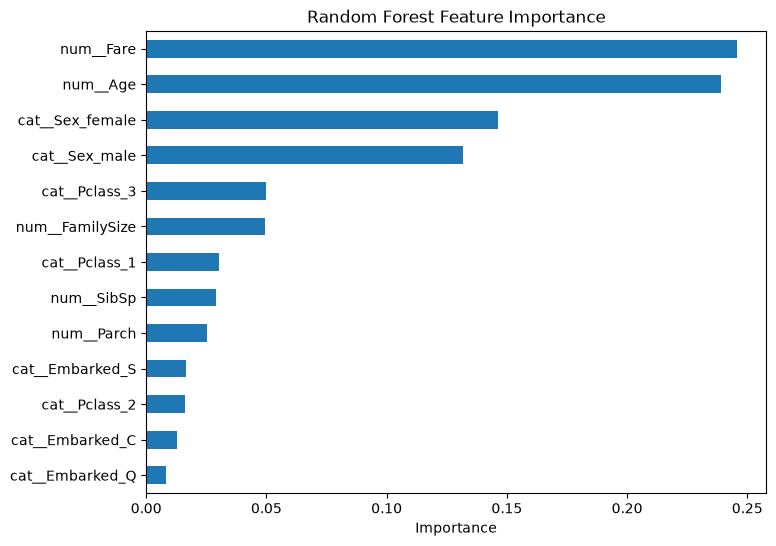

In [72]:
feature_importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

In [73]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_val,
    y_val,
    n_repeats=20,
    random_state=42,
    scoring="accuracy"
)

In [74]:
perm_importance = pd.Series(
    perm.importances_mean,
    index=X_val.columns
).sort_values(ascending=False)

print(perm_importance)

Sex            0.184078
Age            0.062291
Fare           0.061453
Pclass         0.045810
Embarked       0.015922
Parch          0.008380
FamilySize     0.008101
PassengerId    0.000000
Name           0.000000
Ticket         0.000000
Cabin          0.000000
SibSp         -0.000279
dtype: float64


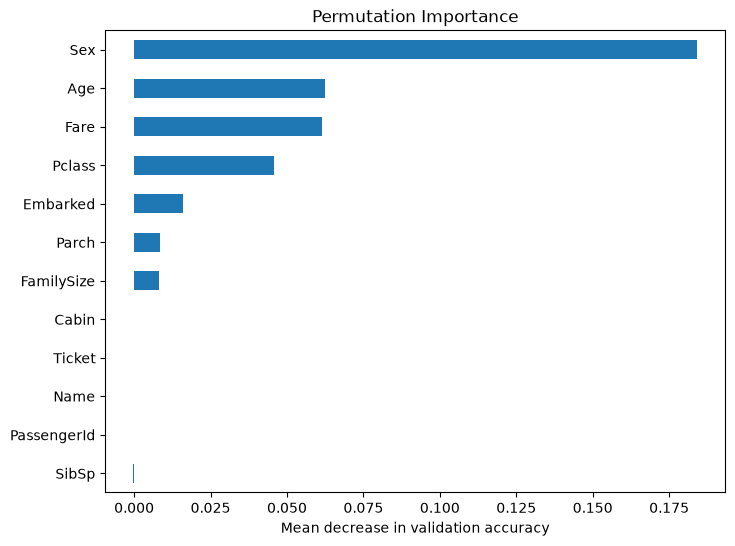

In [75]:
perm_importance.sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.title("Permutation Importance")
plt.xlabel("Mean decrease in validation accuracy")
plt.show()

In [80]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'FamilySize'],
      dtype='str')

In [81]:
train["Title"] = train["Name"].str.extract(
    r",\s*([^.]*)\."
)[0]

In [82]:
print(train["Title"].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [84]:
%whos

Variable                 Type                 Data/Info
-------------------------------------------------------
ColumnTransformer        ABCMeta              <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay   type                 <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier   ABCMeta              <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
GridSearchCV             ABCMeta              <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
KNeighborsClassifier     ABCMeta              <class 'sklearn.neighbors<...>on.KNeighborsClassifier'>
LogisticRegression       type                 <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder            type                 <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                 ABCMeta              <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier   ABCMeta              <class 'sklearn.ensemble.<...>.RandomForestCla

In [85]:
X["Title"] = X["Name"].str.extract(
    r",\s*([^.]*)\."
)[0]

In [86]:
print(X["Title"].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [87]:
X["Title"] = X["Name"].str.extract(
    r",\s*([^.]*)\."
)[0]

print(X["Title"].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [88]:
X["Title"] = X["Name"].str.extract(
    r",\s*([^.]*)\."
)[0].str.strip()

X["Title"] = X["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

In [89]:
common_titles = ["Mr", "Miss", "Mrs", "Master"]

X["Title"] = X["Title"].where(
    X["Title"].isin(common_titles),
    "Rare"
)

In [90]:
print(X["Title"].value_counts())

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


In [92]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [93]:
print(X.columns)

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked', 'FamilySize', 'Title'],
      dtype='str')


In [94]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "Title"
]

X_train_model = X_train[features]
X_val_model = X_val[features]

print(X_train_model.shape)
print(X_val_model.shape)

(712, 9)
(179, 9)


In [96]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [97]:
print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(712, 13)
(179, 13)
(712,)
(179,)


In [98]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "Title"
]

X_train_model = X_train[features]
X_val_model = X_val[features]

print(X_train_model.shape)
print(X_val_model.shape)

(712, 9)
(179, 9)


In [99]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

categorical_features = [
    "Sex",
    "Embarked",
    "Title"
]

In [100]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_title = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [101]:
from sklearn.ensemble import RandomForestClassifier

rf_title = Pipeline([
    ("preprocessor", preprocessor_title),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

In [102]:
rf_title.fit(X_train_model, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Pclass','Sex','Age',...,'Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

In [103]:
rf_title_pred = rf_title.predict(X_val_model)

In [104]:
from sklearn.metrics import accuracy_score, classification_report

print(
    "Random Forest + Title validation accuracy:",
    accuracy_score(y_val, rf_title_pred)
)

print(
    classification_report(
        y_val,
        rf_title_pred,
        target_names=["Did not survive", "Survived"]
    )
)

Random Forest + Title validation accuracy: 0.8212290502793296
                 precision    recall  f1-score   support

Did not survive       0.84      0.87      0.86       110
       Survived       0.78      0.74      0.76        69

       accuracy                           0.82       179
      macro avg       0.81      0.81      0.81       179
   weighted avg       0.82      0.82      0.82       179



In [105]:
X["CabinKnown"] = X["Cabin"].notna().astype(int)

X["CabinDeck"] = X["Cabin"].str[0]

X["TicketGroupSize"] = X.groupby("Ticket")["Ticket"].transform("count")

In [106]:
print(X[[
    "Cabin",
    "CabinKnown",
    "CabinDeck",
    "Ticket",
    "TicketGroupSize"
]].head(15))

   Cabin  CabinKnown CabinDeck            Ticket  TicketGroupSize
0    NaN           0       NaN         A/5 21171                1
1    C85           1         C          PC 17599                1
2    NaN           0       NaN  STON/O2. 3101282                1
3   C123           1         C            113803                2
4    NaN           0       NaN            373450                1
5    NaN           0       NaN            330877                1
6    E46           1         E             17463                1
7    NaN           0       NaN            349909                4
8    NaN           0       NaN            347742                3
9    NaN           0       NaN            237736                2
10    G6           1         G           PP 9549                2
11  C103           1         C            113783                1
12   NaN           0       NaN         A/5. 2151                1
13   NaN           0       NaN            347082                7
14   NaN  

In [107]:
print(X["CabinDeck"].value_counts(dropna=False))

CabinDeck
NaN    687
C       59
B       47
D       33
E       32
A       15
F       13
G        4
T        1
Name: count, dtype: int64


In [108]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [109]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "Title",
    "CabinKnown",
    "CabinDeck",
    "TicketGroupSize"
]

X_train_model = X_train[features]
X_val_model = X_val[features]

In [110]:
numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "CabinKnown",
    "TicketGroupSize"
]

categorical_features = [
    "Sex",
    "Embarked",
    "Title",
    "CabinDeck"
]

In [111]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_expanded = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [112]:
from sklearn.ensemble import RandomForestClassifier

rf_expanded = Pipeline([
    ("preprocessor", preprocessor_expanded),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

rf_expanded.fit(X_train_model, y_train)

rf_expanded_pred = rf_expanded.predict(X_val_model)

In [113]:
from sklearn.metrics import accuracy_score, classification_report

print(
    "Expanded Random Forest validation accuracy:",
    accuracy_score(y_val, rf_expanded_pred)
)

print(
    classification_report(
        y_val,
        rf_expanded_pred,
        target_names=["Did not survive", "Survived"]
    )
)

Expanded Random Forest validation accuracy: 0.7821229050279329
                 precision    recall  f1-score   support

Did not survive       0.80      0.86      0.83       110
       Survived       0.75      0.65      0.70        69

       accuracy                           0.78       179
      macro avg       0.77      0.76      0.76       179
   weighted avg       0.78      0.78      0.78       179



In [115]:
features_without_extra = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "Title"
]

In [116]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_title,
    X[features_without_extra],
    y,
    cv=5,
    scoring="accuracy"
)

print("CV scores:", cv_scores)
print("Mean CV accuracy:", cv_scores.mean())
print("Std:", cv_scores.std())

CV scores: [0.79888268 0.79213483 0.84269663 0.76404494 0.80898876]
Mean CV accuracy: 0.8013495700207143
Std: 0.02549732797990783


In [117]:
print(test.shape)
print(test.columns)

(418, 11)
Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')


In [118]:
test["Title"] = test["Name"].str.extract(
    r",\s*([^.]*)\."
)[0].str.strip()

test["Title"] = test["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

common_titles = ["Mr", "Miss", "Mrs", "Master"]

test["Title"] = test["Title"].where(
    test["Title"].isin(common_titles),
    "Rare"
)

In [119]:
print(test["Title"].value_counts())

Title
Mr        240
Miss       79
Mrs        72
Master     21
Rare        6
Name: count, dtype: int64


In [120]:
test["FamilySize"] = test["SibSp"] + test["Parch"] + 1

In [121]:
print(test["FamilySize"].describe())

count    418.000000
mean       1.839713
std        1.519072
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       11.000000
Name: FamilySize, dtype: float64


In [122]:
features_final = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "Title"
]

X_test_final = test[features_final]

print(X_test_final.shape)
print(X_test_final.head())

(418, 9)
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked  FamilySize Title
0       3    male  34.5      0      0   7.8292        Q           1    Mr
1       3  female  47.0      1      0   7.0000        S           2   Mrs
2       2    male  62.0      0      0   9.6875        Q           1    Mr
3       3    male  27.0      0      0   8.6625        S           1    Mr
4       3  female  22.0      1      1  12.2875        S           3   Mrs


In [123]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

In [124]:
numeric_features_final = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

In [125]:
categorical_features_final = [
    "Sex",
    "Embarked",
    "Title"
]

In [126]:
numeric_transformer_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("num", numeric_transformer_final, numeric_features_final),
    ("cat", categorical_transformer_final, categorical_features_final)
])

In [127]:
final_model = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

In [128]:
X_final = X[features_final]

final_model.fit(X_final, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Pclass','Sex','Age',...,'Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

In [129]:
test_predictions = final_model.predict(X_test_final)

In [130]:
print(test_predictions.shape)
print(pd.Series(test_predictions).value_counts())

(418,)
0    260
1    158
Name: count, dtype: int64


In [131]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

In [132]:
print(submission.head())
print(submission.shape)

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         1
4          896         0
(418, 2)


In [133]:
submission.to_csv(
    "submission.csv",
    index=False
)

In [134]:
print(submission.head(10))

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         1
4          896         0
5          897         0
6          898         0
7          899         0
8          900         1
9          901         0


In [135]:
print(submission.shape)
print(submission["Survived"].value_counts())
print(submission.isna().sum())

(418, 2)
Survived
0    260
1    158
Name: count, dtype: int64
PassengerId    0
Survived       0
dtype: int64


In [136]:
import os

print(os.path.exists("submission.csv"))
print(os.path.getsize("submission.csv"))

True
3258
